# ML7 — Sensitivity to the purchase value (raw / binary / log)

**Project:** DS 5020 Mini-Project "Customers Like You".

DE4 built three matrices on the **identical sparsity pattern**: `A_raw` (total quantity), `A_binary` (1 if bought),
`A_log` (`log1p(total quantity)`, the main value). This notebook asks how much that choice matters.

For each value: `TruncatedSVD(50, randomized, n_iter=7, seed 42)` fitted on that matrix; product vectors
`components_.T` with unit-norm rows (weighting `V`); customer scoring rows taken from the **same** matrix;
already-bought products excluded; top 10. Everything goes through `src/recommend.py` and `src/evaluate.py` unchanged.

Outputs: `reports/ml7_sensitivity.csv`, `reports/figures/ml7_sensitivity.png`. No winner is chosen here.

In [1]:
# Environment guard: this notebook must run in the "giftlane" conda env (pandas 3.0.6).
# It fails fast with "Wrong Python environment. Run: conda activate giftlane" otherwise.
import sys
from pathlib import Path

_ROOT = Path.cwd().resolve()
if _ROOT.name == "notebooks":
    _ROOT = _ROOT.parent
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from src.env_check import check_env

print("environment OK:", check_env())

environment OK: /opt/homebrew/Caskroom/miniforge/base/envs/giftlane/bin/python


## 0. Setup and inputs

In [2]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
import numpy as np
import pandas as pd
import scipy.sparse as sp
import sklearn

from src.svd import SEED, N_ITER, load_inputs, total_energy, energy_kept, rel_error, top_products_for_component
from src.recommend import fit_recommender, recommend_for_customers, describe_cols, customer_top_bought, assert_no_bought_in_recs
from src.evaluate import TOP_N, build_eval_set, evaluate_baseline, paired_bootstrap, per_customer_metrics

ROOT = _ROOT
PROCESSED = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
FIG_DIR = REPORTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)

K = 50
VALUES = ("raw", "binary", "log")
A_log, product_index, customer_index = load_inputs(ROOT)
matrices = {
    "raw": sp.load_npz(PROCESSED / "A_raw.npz").tocsr(),
    "binary": sp.load_npz(PROCESSED / "A_binary.npz").tocsr(),
    "log": A_log,
}
targets = pd.read_parquet(PROCESSED / "test_targets.parquet")
ev = build_eval_set(targets, customer_index, product_index)

print("python  :", sys.executable)
print(f"sklearn : {sklearn.__version__} | numpy : {np.__version__} | pandas : {pd.__version__}")
for v, A in matrices.items():
    assert A.shape == A_log.shape and A.nnz == A_log.nnz
    assert (A.indptr == A_log.indptr).all() and (A.indices == A_log.indices).all(), f"{v}: sparsity pattern differs"
    print(f"A_{v:<6}: {A.shape[0]:,} x {A.shape[1]:,}, nnz {A.nnz:,} | values min {A.data.min():.3f} / median {np.median(A.data):.3f} / max {A.data.max():,.3f} | ||A||_F^2 = {total_energy(A):,.1f}")
print("identical sparsity pattern across the three matrices: OK")
print(f"eval set: {ev.n_eval:,} customers, {int(ev.n_targets.sum()):,} target pairs, ceiling {ev.ceiling_pct:.2f}%")
assert ev.n_eval == 1931

python  : /opt/homebrew/Caskroom/miniforge/base/envs/giftlane/bin/python
sklearn : 1.9.1 | numpy : 2.4.6 | pandas : 3.0.6
A_raw   : 5,471 x 3,687, nnz 413,706 | values min 1.000 / median 6.000 / max 74,215.000 | ||A||_F^2 = 15,912,442,629.0
A_binary: 5,471 x 3,687, nnz 413,706 | values min 1.000 / median 1.000 / max 1.000 | ||A||_F^2 = 413,706.0
A_log   : 5,471 x 3,687, nnz 413,706 | values min 0.693 / median 1.946 / max 11.215 | ||A||_F^2 = 2,389,340.1
identical sparsity pattern across the three matrices: OK
eval set: 1,931 customers, 49,647 target pairs, ceiling 99.07%


## 1. Fit, score and evaluate each value

Same code path as ML4 (`fit_recommender` → `recommend_for_customers` → `per_customer_metrics`); only the matrix changes.

In [3]:
recs_by_value, pc_by_value, rows = {}, {}, {}
for v in VALUES:
    A = matrices[v]
    rec = fit_recommender(A, product_index, k=K, weighting="V", seed=SEED, n_iter=N_ITER)
    recs, _, score_s = recommend_for_customers(rec, ev.rows, n=TOP_N)
    assert_no_bought_in_recs(rec, ev.rows, recs)
    pc = per_customer_metrics(recs, ev, TOP_N)
    energy = total_energy(A)
    recs_by_value[v], pc_by_value[v] = rec, pc
    rows[v] = {
        "value": v, **pc.summary(ev.reachable),
        "total_hits": int(pc.hits.sum()),
        "rel_error": rel_error(rec.svd.singular_values_, energy),
        "energy_kept_pct": 100 * energy_kept(rec.svd.singular_values_, energy),
        "sigma1_share_pct": 100 * rec.svd.singular_values_[0] ** 2 / energy,
        "fit_s": round(rec.fit_seconds, 3), "score_eval_s": round(score_s, 3),
    }
    r = rows[v]
    print(f"{v:<7} hit@10 {r['hit@10']:6.2f}%  recall@10 {r['recall@10']:5.2f}%  precision@10 {r['precision@10']:5.2f}%  | "
          f"rel_error {r['rel_error']:.4f}  energy kept {r['energy_kept_pct']:6.2f}%  (sigma_1 alone {r['sigma1_share_pct']:5.2f}%)  | fit {r['fit_s']:.3f}s")

base_row, base_pc, base_recs = evaluate_baseline(recs_by_value["log"], ev, TOP_N)
rows["baseline"] = {"value": "best-seller baseline", **{k: base_row[k] for k in ("hit@10", "recall@10", "precision@10", "hit@10_reachable")},
                    "total_hits": int(base_pc.hits.sum()), "rel_error": np.nan, "energy_kept_pct": np.nan, "sigma1_share_pct": np.nan,
                    "fit_s": 0.0, "score_eval_s": base_row["score_eval_s"]}
print(f"{'baseline':<7} hit@10 {base_row['hit@10']:6.2f}%  recall@10 {base_row['recall@10']:5.2f}%  precision@10 {base_row['precision@10']:5.2f}%")

results = pd.DataFrame(list(rows.values()))
ml4 = pd.read_csv(REPORTS / "ml4_results.csv").set_index("config")
assert abs(ml4.loc["SVD k=50 V log", "hit@10"] - rows["log"]["hit@10"]) < 1e-9, "log row should reproduce ML4"
print("\nlog reproduces ML4 'SVD k=50 V log' exactly: OK")

raw     hit@10  12.17%  recall@10  0.73%  precision@10  1.43%  | rel_error 0.1860  energy kept  96.54%  (sigma_1 alone 34.62%)  | fit 0.105s


binary  hit@10  23.87%  recall@10  2.61%  precision@10  3.64%  | rel_error 0.8321  energy kept  30.77%  (sigma_1 alone 11.78%)  | fit 0.102s


log     hit@10  21.44%  recall@10  2.35%  precision@10  3.15%  | rel_error 0.7892  energy kept  37.71%  (sigma_1 alone 13.02%)  | fit 0.101s


baseline hit@10  26.77%  recall@10  1.74%  precision@10  3.62%

log reproduces ML4 'SVD k=50 V log' exactly: OK


## 2. Results table

`rel_error = sqrt(1 - Σσ²/‖A‖²_F)` and energy kept are **not comparable across values** as quality measures: each matrix has
its own norm. `sigma1_share_pct` (how much of the energy the first component alone holds) shows how dominated a matrix is
by a single direction.

In [4]:
show = results[["value", "hit@10", "recall@10", "precision@10", "hit@10_reachable", "total_hits", "rel_error", "energy_kept_pct", "sigma1_share_pct", "fit_s"]]
print(show.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
csv_path = REPORTS / "ml7_sensitivity.csv"
results.to_csv(csv_path, index=False)
print(f"\nsaved -> {csv_path.relative_to(ROOT)}")

               value  hit@10  recall@10  precision@10  hit@10_reachable  total_hits  rel_error  energy_kept_pct  sigma1_share_pct  fit_s
                 raw  12.170      0.729         1.434            12.284         277      0.186           96.541            34.616  0.105
              binary  23.874      2.608         3.641            24.098         703      0.832           30.768            11.775  0.102
                 log  21.440      2.351         3.154            21.641         609      0.789           37.712            13.024  0.101
best-seller baseline  26.774      1.739         3.620            27.026         699        NaN              NaN               NaN  0.000

saved -> reports/ml7_sensitivity.csv


## 3. Component 1 under each value (top 10 products by |weight|)

In [5]:
for v in VALUES:
    rec = recs_by_value[v]
    tbl = top_products_for_component(rec.svd, product_index, component=0, n=10)
    signs = np.sign(rec.svd.components_[0])
    print(f"=== {v}: component 1 (sigma_1^2 = {rows[v]['sigma1_share_pct']:.2f}% of energy; "
          f"{int((signs > 0).sum()):,} positive / {int((signs < 0).sum()):,} negative weights) ===")
    print(tbl.to_string())
    print()

=== raw: component 1 (sigma_1^2 = 34.62% of energy; 3,687 positive / 0 negative weights) ===
     StockCode                         Description    weight  n_customers_train
rank                                                                           
1        23166      MEDIUM CERAMIC TOP STORAGE JAR  0.999998                107
2        21212    PACK OF 72 RETRO SPOT CAKE CASES  0.000789               1058
3        21977  PACK OF 60 PINK PAISLEY CAKE CASES  0.000654                722
4        15036           ASSORTED COLOURS SILK FAN  0.000343                285
5        84991         60 TEATIME FAIRY CAKE CASES  0.000337                784
6        21166          COOK WITH WINE METAL SIGN   0.000308                444
7        84992      72 SWEETHEART FAIRY CAKE CASES  0.000277                578
8        22629                 SPACEBOY LUNCH BOX   0.000257                419
9        21975      PACK OF 60 DINOSAUR CAKE CASES  0.000237                520
10      85099B             

## 4. Paired bootstrap vs log (1,000 resamples, seed 42)

Differences in percentage points, raw − log and binary − log, over the same 1,931 customers.

In [6]:
boot = []
for v in ("raw", "binary"):
    b = paired_bootstrap(pc_by_value[v], pc_by_value["log"], n_boot=1000, seed=SEED)
    b.insert(0, "comparison", f"{v} minus log")
    boot.append(b)
boot = pd.concat(boot, ignore_index=True)
print(boot.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

      comparison    metric  mean_diff_pp  ci95_low_pp  ci95_high_pp  share_resamples_diff_gt_0  n_customers  n_boot
   raw minus log    hit@10        -9.270      -11.187        -7.249                      0.000         1931    1000
   raw minus log recall@10        -1.622       -2.013        -1.245                      0.000         1931    1000
binary minus log    hit@10         2.434        0.722         4.144                      0.997         1931    1000
binary minus log recall@10         0.257       -0.069         0.567                      0.943         1931    1000


## 5. The same three customers as ML3 (rows 0, 1000, 3000)

Customers are identified by **matrix row index only**. Row 0 contains the single largest cell in the matrix
(a 74,215-unit order of one product). Under `raw` that one cell is almost the whole row; under `log` it is ln(74,216) ≈ 11.2
against a typical 1–3; under `binary` it is just 1 like every other product. The top-10 lists below show whether that
order steers the recommendations.

In [7]:
ROWS = [0, 1000, 3000]
for row in ROWS:
    print("#" * 100)
    nnz = A_log.indptr[row + 1] - A_log.indptr[row]
    raw_vals = matrices["raw"].getrow(row).data
    share_top = raw_vals.max() / raw_vals.sum()
    norm_share = raw_vals.max() ** 2 / np.sum(raw_vals ** 2)
    print(f"row {row}: {nnz} distinct products in train | raw quantities: max {raw_vals.max():,.0f}, median {np.median(raw_vals):.0f} | "
          f"largest product = {100*share_top:.1f}% of units and {100*norm_share:.1f}% of the raw row's squared norm")
    print("  top bought (by A_log value):")
    print("  " + customer_top_bought(recs_by_value["log"], row, n=3)[["StockCode", "Description", "approx_total_qty", "n_customers_train"]]
          .to_string().replace("\n", "\n  "))
    lists = {}
    for v in VALUES:
        idx, sc, _ = recommend_for_customers(recs_by_value[v], np.array([row]), n=TOP_N)
        lists[v] = idx[0]
        print(f"\n  top-10 recommendations under {v}:")
        print("  " + describe_cols(recs_by_value[v], idx[0], sc[0])[["StockCode", "Description", "n_customers_train", "score"]]
              .to_string(float_format=lambda x: f"{x:.3f}").replace("\n", "\n  "))
    ov = {f"{a}∩{b}": len(set(lists[a]) & set(lists[b])) for a, b in (("raw", "log"), ("binary", "log"), ("raw", "binary"))}
    print(f"\n  overlap of the three top-10 lists: {ov}")
    print()

####################################################################################################
row 0: 25 distinct products in train | raw quantities: max 74,215, median 1 | largest product = 100.0% of units and 100.0% of the raw row's squared norm
  top bought (by A_log value):
       StockCode                     Description  approx_total_qty  n_customers_train
  rank                                                                               
  1        23166  MEDIUM CERAMIC TOP STORAGE JAR             74215                107
  2      15056BL         EDWARDIAN PARASOL BLACK                 1                301
  3       15056N       EDWARDIAN PARASOL NATURAL                 1                331

  top-10 recommendations under raw:
       StockCode                        Description  n_customers_train  score
  rank                                                                       
  1        23142       IVORY WIRE KITCHEN ORGANISER                 31 35.340
  2        359

## 6. Figure

saved -> reports/figures/ml7_sensitivity.png


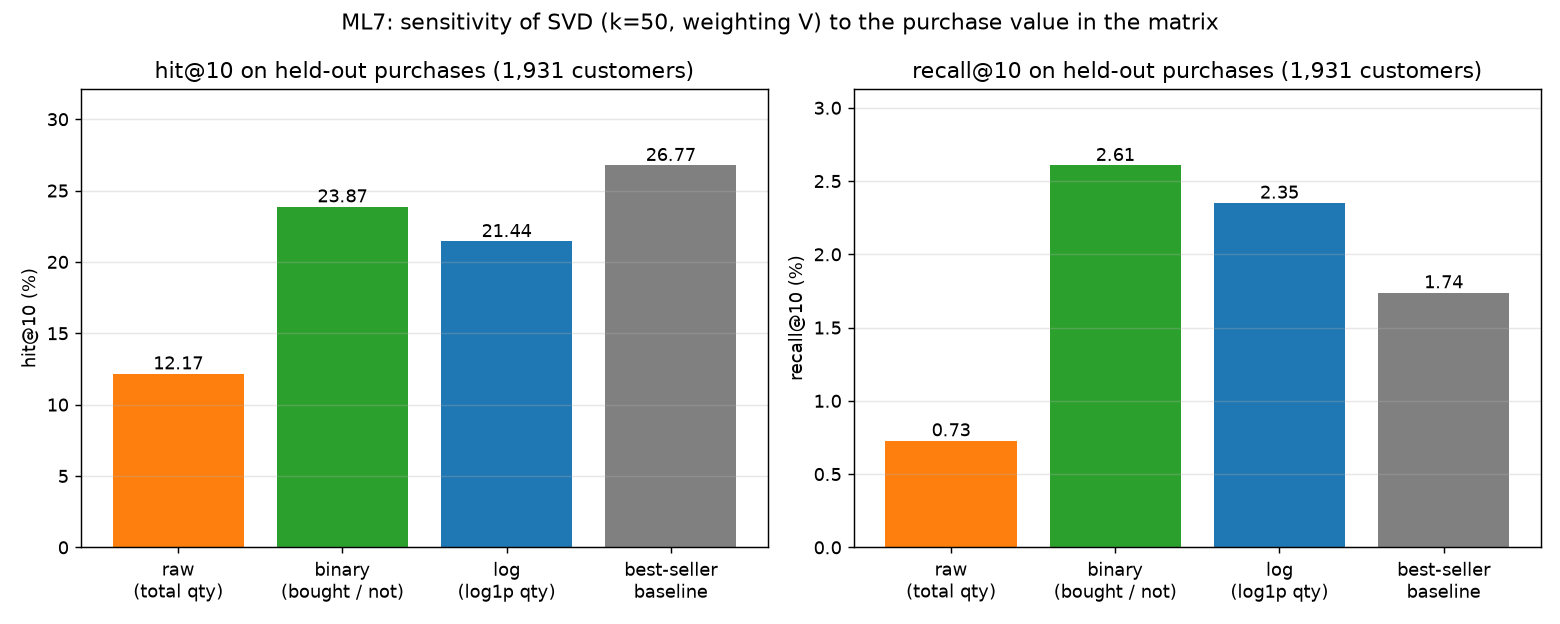

In [8]:
order = ["raw", "binary", "log", "best-seller baseline"]
plot_df = results.set_index("value").loc[order]
colors = ["tab:orange", "tab:green", "tab:blue", "grey"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, metric in zip(axes, ["hit@10", "recall@10"]):
    vals = plot_df[metric].to_numpy()
    bars = ax.bar(range(len(order)), vals, color=colors)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(["raw\n(total qty)", "binary\n(bought / not)", "log\n(log1p qty)", "best-seller\nbaseline"], fontsize=10)
    ax.set_ylabel(f"{metric} (%)")
    ax.set_title(f"{metric} on held-out purchases ({ev.n_eval:,} customers)")
    ax.set_ylim(0, vals.max() * 1.2)
    ax.grid(True, axis="y", alpha=0.3)
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:.2f}", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom", fontsize=10)
fig.suptitle(f"ML7: sensitivity of SVD (k={K}, weighting V) to the purchase value in the matrix", fontsize=12)
fig.tight_layout()
fig_path = FIG_DIR / "ml7_sensitivity.png"
fig.savefig(fig_path, dpi=130)
plt.close(fig)
print(f"saved -> {fig_path.relative_to(ROOT)}")
display(Image(filename=str(fig_path), width=900))

## Stop here

The table, bootstrap and the three worked examples are the evidence; the choice of value is recorded by the author in
`decision_log.md`, not here.